In [1]:
#Can comment out once installed once
#!pip install yfinance
#!pip install pandas
#!pip install matplotlib

In [2]:
import yfinance as yf
import pandas as pd
import matplotlib.pyplot as plt

In [3]:
# Fetch historical data
stock_symbol = "AAPL"  # Change this to any stock symbol
start_date = "2020-01-01"
end_date = "2025-03-28"


df = yf.download(stock_symbol, start=start_date, end=end_date)

YF.download() has changed argument auto_adjust default to True


[*********************100%***********************]  1 of 1 completed


In [4]:
# Calculate Moving Averages
df['SMA_10'] = df['Close'].rolling(window=10).mean()
df['SMA_50'] = df['Close'].rolling(window=50).mean()

In [5]:
# Generate Buy/Sell signals
df['Signal'] = 0
df.loc[df['SMA_10'] > df['SMA_50'], 'Signal'] = 1  # Buy Signal
df.loc[df['SMA_10'] < df['SMA_50'], 'Signal'] = -1  # Sell Signal

In [6]:
# Reduce excessive signals (filter for significant changes)
df['Filtered_Signal'] = df['Signal'].where(df['Signal'] != df['Signal'].shift(), 0)
filtered_signals_df = df[df['Filtered_Signal'] != 0][['Close', 'SMA_10', 'SMA_50', 'Filtered_Signal']]
filtered_signals_df['Action'] = filtered_signals_df['Filtered_Signal'].map({1: 'Buy', -1: 'Sell'})

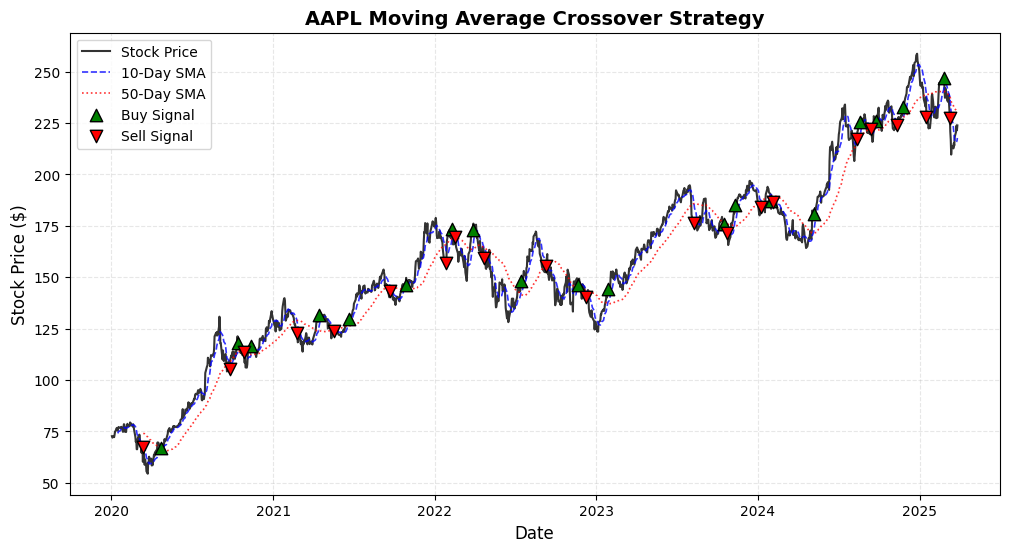

In [7]:
# Plot the results
plt.figure(figsize=(12, 6))
plt.plot(df.index, df['Close'], label="Stock Price", color="black", linewidth=1.5, alpha=0.8)
plt.plot(df.index, df['SMA_10'], label="10-Day SMA", linestyle='dashed', color='blue', linewidth=1.2, alpha=0.8)
plt.plot(df.index, df['SMA_50'], label="50-Day SMA", linestyle='dotted', color='red', linewidth=1.2, alpha=0.8)

# Plot Buy and Sell signals
plt.scatter(filtered_signals_df.index[filtered_signals_df['Filtered_Signal'] == 1], filtered_signals_df['Close'][filtered_signals_df['Filtered_Signal'] == 1], label="Buy Signal", marker="^", color="green", edgecolors="black", s=80, zorder=3)
plt.scatter(filtered_signals_df.index[filtered_signals_df['Filtered_Signal'] == -1], filtered_signals_df['Close'][filtered_signals_df['Filtered_Signal'] == -1], label="Sell Signal", marker="v", color="red", edgecolors="black", s=80, zorder=3)

plt.title(f"{stock_symbol} Moving Average Crossover Strategy", fontsize=14, fontweight='bold')
plt.xlabel("Date", fontsize=12)
plt.ylabel("Stock Price ($)", fontsize=12)
plt.legend(fontsize=10)
plt.grid(True, linestyle='--', alpha=0.3)
plt.show()

In [8]:
# Display as a table
print(filtered_signals_df.tail(10).to_string())  # Show last 10 significant signals

Price            Close      SMA_10      SMA_50 Filtered_Signal Action
Ticker            AAPL                                               
Date                                                                 
2024-05-06  180.856033  171.824672  171.562112               1    Buy
2024-08-12  217.052292  214.554080  214.564702              -1   Sell
2024-08-19  225.393921  217.800766  217.553975               1    Buy
2024-09-13  222.011368  221.988431  222.465005              -1   Sell
2024-09-23  225.972656  222.049292  221.766512               1    Buy
2024-11-11  223.983734  225.497346  226.236207              -1   Sell
2024-11-25  232.614243  227.662689  227.624102               1    Buy
2025-01-16  228.009308  238.515758  238.854897              -1   Sell
2025-02-24  247.100006  241.109000  240.485810               1    Buy
2025-03-10  227.479996  237.812000  238.053778              -1   Sell
